# 8. Predicting friction instead of a family

A family (wood, metal...) is a label we chose. Friction is measured by an instrument: several datasets record the
forces while the tool or the finger slides, so each surface has a friction coefficient.

Question: if we learn "vibration -> friction" on one dataset, does it still rank the surfaces of another
dataset, with no label from it?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline

## The data

From `1_data.ipynb`:

- one BEATs vector per recording of the vibration (everything brought down to 3 kHz, the rate of TUM);
- the measured friction of each surface (median of tangential force / normal force while pressing).

HaTT, LMT69 and TUM are steel tips held by hand. SENS3 and Devillard are bare fingers. Cluster is a machine.

In [2]:
friction = pd.read_csv("cache/measured_friction.csv", dtype={"surface": str})


def load(dataset, file="cache/vibration_vectors_3khz.npz"):
    # one vector per surface (mean of its recordings), standardized, with the log of its friction
    saved = np.load(file, allow_pickle=True)
    rows = saved["dataset"] == dataset
    means = pd.DataFrame(saved["vectors"][rows]).groupby(saved["surface"][rows]).mean()
    means = (means - means.mean()) / (means.std(ddof=0) + 1e-6)
    measured = friction[friction.dataset == dataset].set_index("surface").friction
    surfaces = means.index.intersection(measured.index)
    return means.loc[surfaces].to_numpy(), np.log10(measured[surfaces])


datasets = ["HaTT", "LMT69", "TUM", "SENS3", "Devillard", "Cluster"]
data = {d: load(d) for d in datasets}
pd.Series({d: len(data[d][1]) for d in datasets}, name="surfaces with friction")

HaTT         100
LMT69         69
TUM          200
SENS3         50
Devillard     10
Cluster      118
Name: surfaces with friction, dtype: int64

## The model

30 principal components, then a ridge regression. We score with the Spearman rank correlation between the
predicted and the measured friction: 1 = same order, 0 = nothing, negative = reversed order.

In [3]:
def model():
    return make_pipeline(PCA(30, random_state=0), Ridge(alpha=10.0))


def transfer(source, target):
    predicted = model().fit(*source).predict(target[0])
    return spearmanr(target[1], predicted)[0], predicted


def interval(truth, predicted):
    # draw the surfaces again, 2000 times
    rng = np.random.default_rng(0)
    truth, predicted = np.asarray(truth), np.asarray(predicted)
    draws = []
    for _ in range(2000):
        pick = rng.integers(0, len(truth), len(truth))
        draws.append(spearmanr(truth[pick], predicted[pick])[0])
    return np.percentile(draws, [2.5, 97.5]).round(2)

## Inside one dataset

Surfaces never seen, 5 folds. Devillard has only 10 textures, too few to train on.

In [4]:
folds = KFold(5, shuffle=True, random_state=0)
inside = {}
for d in datasets:
    X, y = data[d]
    if len(y) >= 40:
        inside[d] = spearmanr(y, cross_val_predict(model(), X, y, cv=folds))[0]
pd.Series(inside).round(2)

HaTT       0.62
LMT69      0.46
TUM        0.24
SENS3      0.81
Cluster    0.76
dtype: float64

## From one dataset to another

Train on the row, test on the column. No label of the tested dataset.

In [5]:
sources = [d for d in datasets if len(data[d][1]) >= 40]
matrix = pd.DataFrame(index=sources, columns=datasets, dtype=float)
for s in sources:
    for t in datasets:
        if s != t:
            matrix.loc[s, t] = transfer(data[s], data[t])[0]
matrix.to_csv("results/friction_transfer.csv")
matrix.round(2)

,HaTT,LMT69,TUM,SENS3,Devillard,Cluster
HaTT,NaN,0.50,0.15,0.59,0.87,-0.45
LMT69,0.39,NaN,-0.09,0.52,0.89,-0.45
TUM,0.46,0.24,NaN,-0.55,0.41,-0.36
SENS3,0.41,0.39,0.03,NaN,0.27,-0.70
Cluster,-0.09,-0.29,0.13,-0.46,0.79,NaN


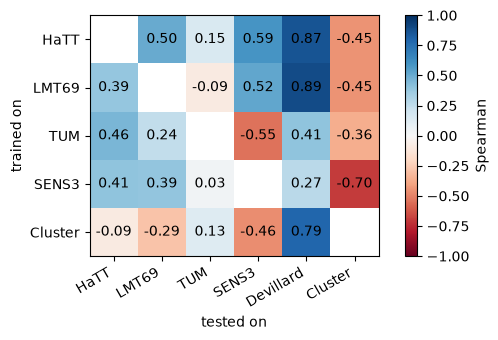

In [6]:
plt.figure(figsize=(6, 3.5))
plt.imshow(matrix, cmap="RdBu", vmin=-1, vmax=1)
plt.xticks(range(len(datasets)), datasets, rotation=30, ha="right")
plt.yticks(range(len(sources)), sources)
for i in range(len(sources)):
    for j in range(len(datasets)):
        if not np.isnan(matrix.iloc[i, j]):
            plt.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center")
plt.xlabel("tested on")
plt.ylabel("trained on")
plt.colorbar(label="Spearman")
plt.tight_layout()
plt.savefig("results/friction_transfer.png", dpi=120)

## Steel tip to bare finger, in detail

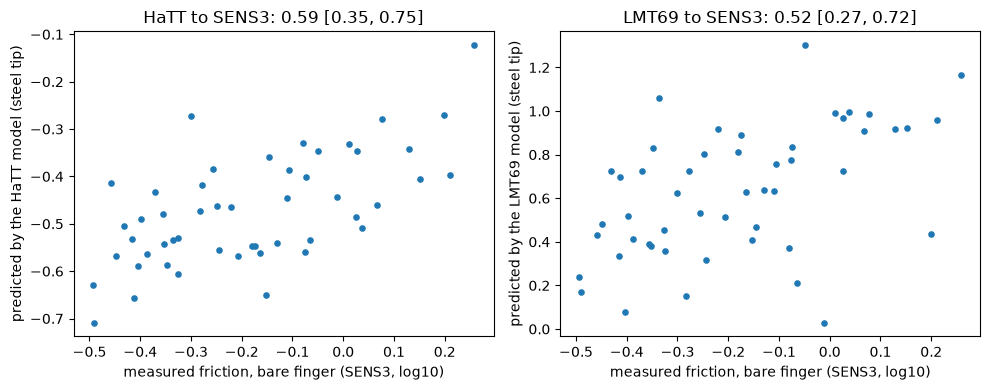

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, source in zip(axes, ["HaTT", "LMT69"]):
    score, predicted = transfer(data[source], data["SENS3"])
    low, high = interval(data["SENS3"][1], predicted)
    ax.scatter(data["SENS3"][1], predicted, s=14)
    ax.set_xlabel("measured friction, bare finger (SENS3, log10)")
    ax.set_ylabel(f"predicted by the {source} model (steel tip)")
    ax.set_title(f"{source} to SENS3: {score:.2f} [{low}, {high}]")
plt.tight_layout()
plt.savefig("results/friction_steel_tip_to_finger.png", dpi=120)

## Two tests with a pass mark written before

**Sound instead of vibration.** Same thing with the microphone, between LMT69 and SENS3.
Pass mark: at least 0.30 in both directions.

In [8]:
sound = {d: load(d, "cache/sound_vectors_beats.npz") for d in ["LMT69", "SENS3"]}
for s, t in [("LMT69", "SENS3"), ("SENS3", "LMT69")]:
    score, predicted = transfer(sound[s], sound[t])
    print(s, "to", t, "with sound:", round(score, 2), interval(sound[t][1], predicted))

LMT69 to SENS3 with sound: 0.28 [-0.02  0.54]


SENS3 to LMT69 with sound: 0.03 [-0.22  0.27]


**The machine dataset.** Cluster gives the friction of its 118 textures. We had never looked at these values.
We train on HaTT + LMT69 + SENS3 together (friction put on the same scale in each) and test on Cluster.
Pass mark: at least +0.30.

In [9]:
X = np.concatenate([data[d][0] for d in ["HaTT", "LMT69", "SENS3"]])
y = np.concatenate([(data[d][1] - data[d][1].mean()) / data[d][1].std() for d in ["HaTT", "LMT69", "SENS3"]])
score, predicted = transfer((X, y), data["Cluster"])
print("HaTT + LMT69 + SENS3 to Cluster:", round(score, 2), interval(data["Cluster"][1], predicted))

HaTT + LMT69 + SENS3 to Cluster: -0.52 [-0.65 -0.36]


## What we see

- Between hand-held setups friction transfers, even from a steel tip to a bare finger (HaTT to SENS3 0.59,
  LMT69 to SENS3 0.52), and again on Devillard (0.87 and 0.89, but only 10 textures).
- It is not perfect inside the hand-held group: TUM to SENS3 is negative (-0.55) and we do not know why.
- With sound it fails (0.28 and 0.03).
- On the machine dataset the order is **reversed** (-0.52), although friction is well predicted inside Cluster.
- So the model does not read "friction" in general. Other checks we ran show that it mostly follows the vibration
  level and the speed of the gesture, which go with friction when a hand holds the tool.
- All of this is exploratory, except the two tests above, and both failed.